# Vanilla Flow Matching: Gaussian → Two Moons

This notebook trains a small neural network to learn a **velocity field** $u_\theta(x, t)$ that
transports samples from a standard Gaussian (time $t=0$) to the two-moons dataset (time $t=1$).

The recipe is:

1. Sample noise $x_0 \sim \mathcal{N}(0, I)$ and data $x_1 \sim p_{\text{moons}}$.
2. Pick a random time $t \in [0,1]$ and form the point on the straight line between them:
   $x_t = (1-t)\,x_0 + t\,x_1$.
3. The "true" velocity along that line is simply $x_1 - x_0$.
4. Train the network so that $u_\theta(x_t, t) \approx x_1 - x_0$ (mean squared error).
5. To **generate** new samples: start from fresh noise and follow the learned velocity field
   from $t=0$ to $t=1$ with a simple ODE solver (Euler steps).

At the end we save a GIF of the samples moving from a Gaussian blob into the two moons.

## 1. Imports and settings

In [2]:
import math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from PIL import Image
import io

torch.manual_seed(0)
np.random.seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cpu


## 2. The target data: two moons

We scale the moons so they are roughly the same size as the Gaussian source (standard deviation ≈ 1).

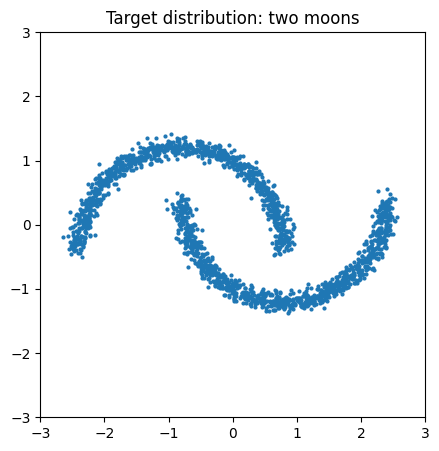

In [3]:
def sample_moons(n):
    # make_moons returns points in roughly [-1, 2] x [-0.5, 1]; we center and scale them.
    x, _ = make_moons(n_samples=n, noise=0.05)
    x = (x - np.array([0.5, 0.25])) * 1.6          # center at the origin, scale up
    return torch.tensor(x, dtype=torch.float32)

data = sample_moons(2000)

plt.figure(figsize=(5, 5))
plt.scatter(data[:, 0], data[:, 1], s=4)
plt.title("Target distribution: two moons")
plt.xlim(-3, 3); plt.ylim(-3, 3); plt.gca().set_aspect("equal")
plt.show()

## 3. The neural network for the velocity field

The network takes a 2D point `x` and a time `t` and outputs a 2D velocity.

* Time is **not** fed in as a raw number. We turn it into a vector of sines and cosines
  (a *sinusoidal embedding*), which lets the network represent fields that change quickly in $t$.
* We use **SiLU** activations (smooth, roughly linear for large inputs).
* **Residual connections** (`h = h + block(h)`) make the network easy to train.
* The last layer starts at zero so the initial velocity field is $u \approx 0$.

In [4]:
class TimeEmbedding(nn.Module):
    '''Turns a scalar time t in [0,1] into a vector of sin/cos features.'''
    def __init__(self, dim=64):
        super().__init__()
        self.dim = dim

    def forward(self, t):                           # t has shape (batch,)
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
        angles = 1000.0 * t[:, None] * freqs[None, :]   # shape (batch, half)
        return torch.cat([angles.sin(), angles.cos()], dim=-1)   # shape (batch, dim)


class VelocityNet(nn.Module):
    '''u_theta(x, t): maps a 2D point and a time to a 2D velocity.'''
    def __init__(self, hidden=128, depth=3, t_dim=64):
        super().__init__()
        self.time_embed = TimeEmbedding(t_dim)
        self.input_layer = nn.Linear(2 + t_dim, hidden)
        self.blocks = nn.ModuleList(
            [nn.Sequential(nn.SiLU(), nn.Linear(hidden, hidden)) for _ in range(depth)]
        )
        self.output_layer = nn.Linear(hidden, 2)
        nn.init.zeros_(self.output_layer.weight)    # start with u = 0
        nn.init.zeros_(self.output_layer.bias)

    def forward(self, x, t):
        h = torch.cat([x, self.time_embed(t)], dim=-1)
        h = self.input_layer(h)
        for block in self.blocks:
            h = h + block(h)                        # residual connection
        return self.output_layer(h)


model = VelocityNet().to(device)
print(f"Number of parameters: {sum(p.numel() for p in model.parameters()):,}")

Number of parameters: 58,370


## 4. Training

Each step of the loop does exactly the four things listed at the top of the notebook:
sample $x_0$ and $x_1$, pick $t$, build $x_t$, and regress the network output onto $x_1 - x_0$.

step     0   loss 2.1848
step   500   loss 1.6202
step  1000   loss 1.7217
step  1500   loss 1.5347
step  2000   loss 1.4824
step  2500   loss 1.6355
step  3000   loss 1.4346
step  3500   loss 1.5109
step  4000   loss 1.5368
step  4500   loss 1.5562
step  4999   loss 1.5724


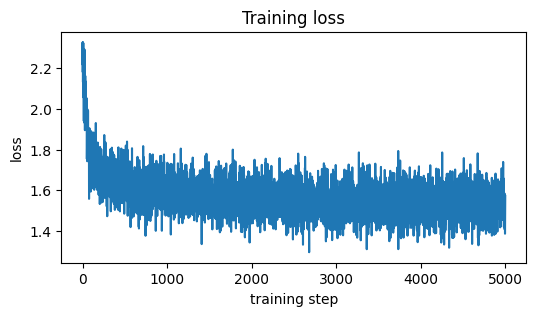

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
n_steps = 5000
batch_size = 512
losses = []

for step in range(n_steps):
    x1 = sample_moons(batch_size).to(device)        # data
    x0 = torch.randn_like(x1)                       # Gaussian noise
    t = torch.rand(batch_size, device=device)       # random times in [0, 1]

    xt = (1 - t[:, None]) * x0 + t[:, None] * x1    # point on the straight line
    target_velocity = x1 - x0                       # direction of that line

    predicted_velocity = model(xt, t)
    loss = ((predicted_velocity - target_velocity) ** 2).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if step % 500 == 0 or step == n_steps - 1:
        print(f"step {step:5d}   loss {loss.item():.4f}")

plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.xlabel("training step"); plt.ylabel("loss"); plt.title("Training loss")
plt.show()

**Why doesn't the loss go to zero?** Many different (noise, data) pairs pass through the same point
$x_t$ at the same time $t$, each with a different target $x_1 - x_0$. The network can only output one
vector per input, so it learns the *average* target, and the leftover spread of the targets around that
average is an irreducible floor in the loss. A loss that plateaus around 1–2 is normal here.

## 5. Generating samples by following the velocity field

Starting from Gaussian noise at $t=0$, we take small Euler steps:
$x \leftarrow x + u_\theta(x, t)\,\Delta t$. We keep every intermediate position so we can animate it.

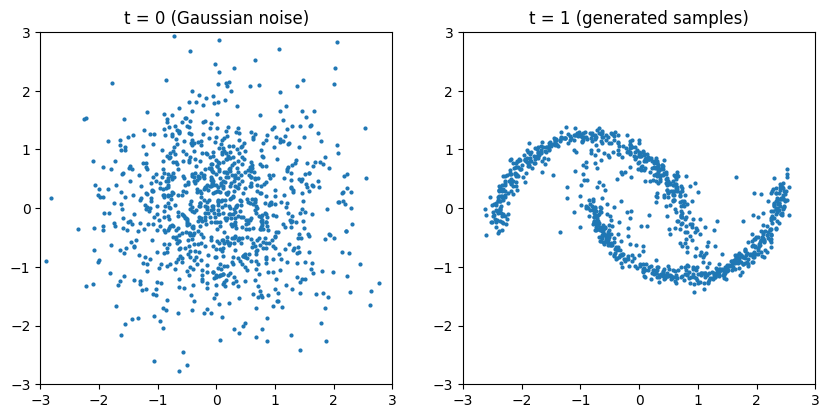

In [6]:
@torch.no_grad()
def generate(model, n_samples=1000, n_steps=100):
    '''Returns a tensor of shape (n_steps + 1, n_samples, 2): the full trajectory.'''
    x = torch.randn(n_samples, 2, device=device)    # start from noise
    dt = 1.0 / n_steps
    trajectory = [x.cpu()]
    for i in range(n_steps):
        t = torch.full((n_samples,), i * dt, device=device)
        x = x + model(x, t) * dt                    # Euler step
        trajectory.append(x.cpu())
    return torch.stack(trajectory)

trajectory = generate(model)
final_samples = trajectory[-1]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].scatter(trajectory[0][:, 0], trajectory[0][:, 1], s=4); axes[0].set_title("t = 0 (Gaussian noise)")
axes[1].scatter(final_samples[:, 0], final_samples[:, 1], s=4);   axes[1].set_title("t = 1 (generated samples)")
for ax in axes:
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.show()

## 6. Make a GIF of the flow

We draw one frame per time step and stitch them together with Pillow.

In [7]:
def make_gif(trajectory, filename="flow_matching_moons.gif", every=2, fps=20):
    frames = []
    n_steps = trajectory.shape[0] - 1
    for i in range(0, n_steps + 1, every):
        t = i / n_steps
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.scatter(trajectory[i][:, 0], trajectory[i][:, 1], s=4, c="tab:blue")
        ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
        ax.set_title(f"t = {t:.2f}")
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=80)
        plt.close(fig)
        buf.seek(0)
        frames.append(Image.open(buf).convert("P"))
    # hold the last frame a bit longer so the final moons are easy to see
    frames += [frames[-1]] * fps
    frames[0].save(filename, save_all=True, append_images=frames[1:],
                   duration=int(1000 / fps), loop=0)
    print("Saved", filename)

make_gif(trajectory)

Saved flow_matching_moons.gif


Open `flow_matching_moons.gif` (or display it below) to watch the Gaussian blob flow into the two moons.

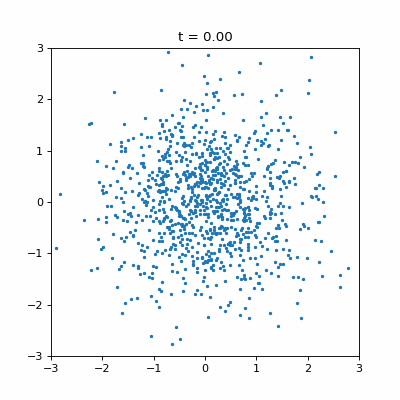

In [8]:
from IPython.display import Image as IPImage
IPImage(filename="flow_matching_moons.gif")

## 7. Velocity field

A quiver plot of $u_\theta(x, t)$ at a few times. Early on the arrows point inward toward the data mean;
later they split and point toward the two crescents.

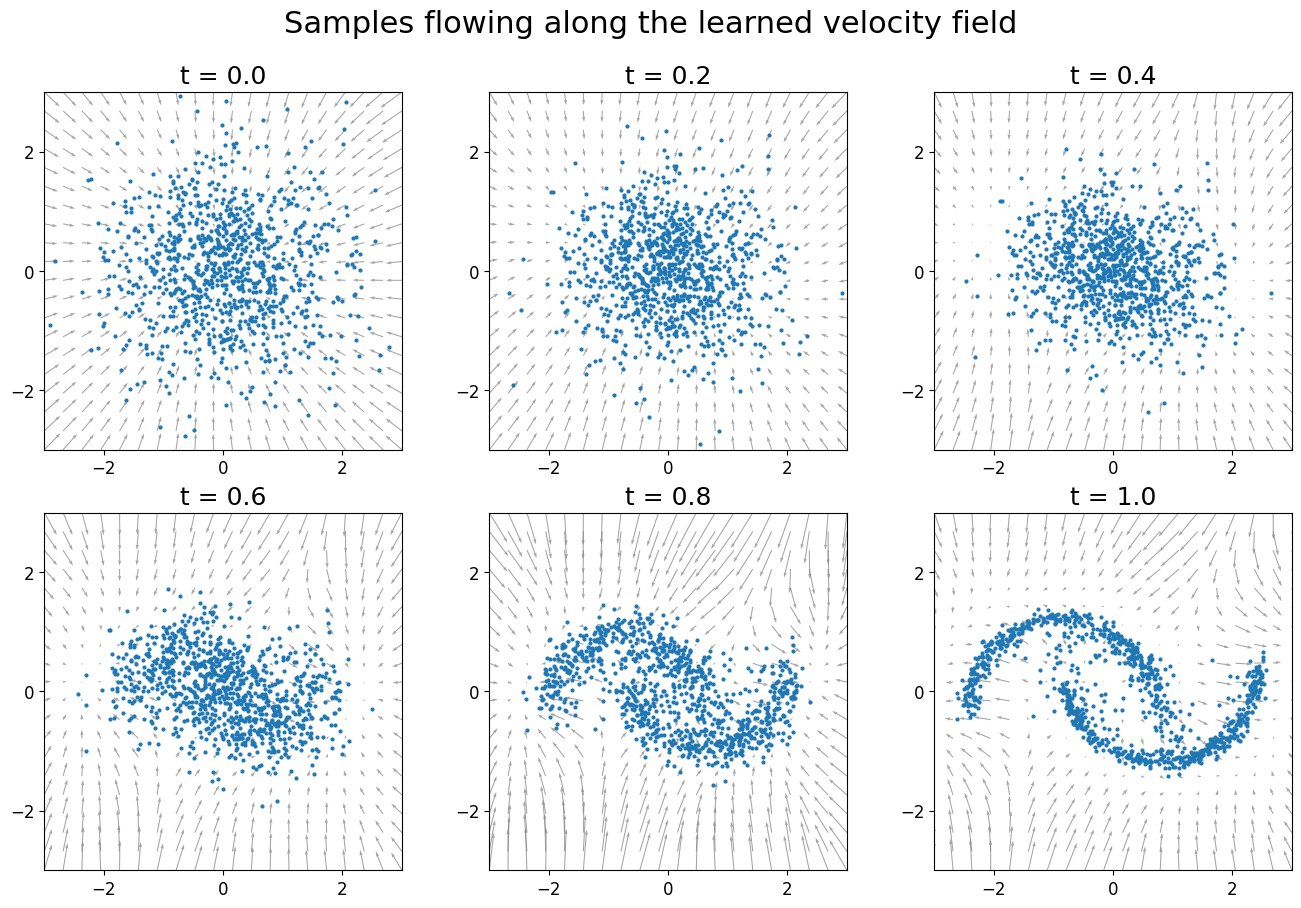

In [9]:
@torch.no_grad()
def plot_flow_with_field(model, trajectory, times=(0.0, 0.2, 0.4, 0.6, 0.8, 1.0),
                         n_rows=2, n_cols=3, grid_size=20, extent=3.0, arrow_scale=12):
    n_steps = trajectory.shape[0] - 1

    # Grid of points where the velocity field is evaluated
    grid = torch.linspace(-extent, extent, grid_size)
    gx, gy = torch.meshgrid(grid, grid, indexing="xy")
    points = torch.stack([gx.flatten(), gy.flatten()], dim=-1).to(device)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.5 * n_rows))
    for ax, t in zip(axes.flatten(), times):
        # The samples at this time, taken from the stored trajectory
        step = round(t * n_steps)
        samples = trajectory[step]

        # The velocity field at this time
        t_batch = torch.full((len(points),), float(t), device=device)
        v = model(points, t_batch).cpu()

        ax.quiver(points[:, 0].cpu(), points[:, 1].cpu(), v[:, 0], v[:, 1],
                  angles="xy", scale_units="xy", scale=arrow_scale,
                  width=0.003, color="gray", alpha=0.7)
        ax.scatter(samples[:, 0], samples[:, 1], s=4, c="tab:blue")

        ax.set_title(f"t = {t:.1f}", fontsize=18)
        ax.set_xlim(-extent, extent); ax.set_ylim(-extent, extent)
        ax.set_aspect("equal")
        ax.set_xticks([-2, 0, 2]); ax.set_yticks([-2, 0, 2])
        ax.tick_params(labelsize=12)

    fig.suptitle("Samples flowing along the learned velocity field", fontsize=22, y=1.0)
    plt.tight_layout()
    fig.savefig("flow_with_field.png", dpi=150, bbox_inches="tight")
    plt.show()

plot_flow_with_field(model, trajectory)